# Práctica de laboratorio: Análisis y visualización de calificaciones con Pandas y Matplotlib
**Asignatura:** Tópicos Avanzados de Programación  
**Nombre:** ______________________  **Número de control:** ____________

## Ejercicio 1. Carga y revisión de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# El archivo debe estar en la misma carpeta que este notebook
df = pd.read_csv("calificaciones_isc.csv")

print("Primeras 5 filas:")
display(df.head())
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
print("\nTipos de dato:")
print(df.dtypes)
print("\nResumen estadístico:")
display(df[["calificacion", "asistencias"]].describe())

Primeras 5 filas:


,matricula,nombre,grupo,materia,unidad,calificacion,asistencias
0,ISC240100,Ana Lopez,A,Programacion,1,55,5
1,ISC240100,Ana Lopez,A,Programacion,2,54,5
2,ISC240100,Ana Lopez,A,Programacion,3,50,8
3,ISC240100,Ana Lopez,A,Bases de datos,1,83,10
4,ISC240100,Ana Lopez,A,Bases de datos,2,86,8


Filas: 288  |  Columnas: 7

Tipos de dato:
matricula         str
nombre            str
grupo             str
materia           str
unidad          int64
calificacion    int64
asistencias     int64
dtype: object

Resumen estadístico:


,calificacion,asistencias
count,288.000000,288.000000
mean,69.548611,7.048611
std,12.476783,1.515678
min,35.000000,3.000000
25%,63.000000,6.000000
50%,70.000000,7.000000
75%,77.250000,8.000000
max,100.000000,10.000000


**¿Por qué hay 288 registros y no 24?** Porque cada alumno aparece una vez por cada materia y por cada unidad: 4 materias × 3 unidades = 12 filas por alumno, y 24 alumnos × 12 filas = 288 registros.

## Ejercicio 2. Filtros (sin modificar `df` y sin ciclos)

In [2]:
solo_a = df[df["grupo"] == "A"]
menores_70 = df[df["calificacion"] < 70]
bd_b_80 = df[
    (df["materia"] == "Bases de datos")
    & (df["grupo"] == "B")
    & (df["calificacion"] >= 80)
]

print("Filas del grupo A:", len(solo_a))
print("Filas con calificación < 70:", len(menores_70))
print("Bases de datos, grupo B, calificación >= 80:", len(bd_b_80))

Filas del grupo A: 144
Filas con calificación < 70: 141
Bases de datos, grupo B, calificación >= 80: 11


## Ejercicio 3. Columna calculada `situacion`

In [3]:
df["situacion"] = np.where(df["calificacion"] >= 70, "Aprobado", "Reprobado")
df[["matricula", "materia", "unidad", "calificacion", "situacion"]].head()

,matricula,materia,unidad,calificacion,situacion
0,ISC240100,Programacion,1,55,Reprobado
1,ISC240100,Programacion,2,54,Reprobado
2,ISC240100,Programacion,3,50,Reprobado
3,ISC240100,Bases de datos,1,83,Aprobado
4,ISC240100,Bases de datos,2,86,Aprobado


## Ejercicio 4. Resúmenes

In [4]:
prom_materia = df.groupby("materia")["calificacion"].mean().round(2)
print("Promedio por materia:")
print(prom_materia)

prom_grupo_materia = df.groupby(["grupo", "materia"])["calificacion"].mean().round(2)
print("\nPromedio por grupo y materia:")
print(prom_grupo_materia)

Promedio por materia:
materia
Bases de datos           70.28
Matematicas discretas    65.08
Programacion             71.21
Redes                    71.62
Name: calificacion, dtype: float64

Promedio por grupo y materia:
grupo  materia              
A      Bases de datos           66.58
       Matematicas discretas    61.25
       Programacion             67.67
       Redes                    67.92
B      Bases de datos           73.97
       Matematicas discretas    68.92
       Programacion             74.75
       Redes                    75.33
Name: calificacion, dtype: float64


In [5]:
prom_alumno = (
    df.groupby(["matricula", "nombre"])["calificacion"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
    .reset_index(name="promedio")   # conserva matrícula y nombre como columnas
)
print("Promedio general por alumno (de mayor a menor):")
display(prom_alumno)

prom_alumno.to_csv("promedios_alumnos.csv", index=False)

Promedio general por alumno (de mayor a menor):


,matricula,nombre,promedio
0,ISC240118,Lucia Aguilar,86.08
1,ISC240115,Emilio Cruz,86.00
2,ISC240116,Regina Navarro,80.33
3,ISC240112,Camila Ortiz,78.92
4,ISC240102,Maria Garcia,77.50
5,ISC240121,Oscar Delgado,76.83
6,ISC240103,Carlos Martinez,75.83
7,ISC240109,Miguel Vargas,74.42
8,ISC240119,Mateo Rios,72.92
9,ISC240100,Ana Lopez,71.25


In [6]:
prom_unidad = df.groupby("unidad")["calificacion"].mean().round(2)
print("Promedio general por unidad:")
print(prom_unidad)

conteo_situacion = df["situacion"].value_counts()
print("\nUnidades aprobadas y reprobadas:")
print(conteo_situacion)

Promedio general por unidad:
unidad
1    67.88
2    70.03
3    70.74
Name: calificacion, dtype: float64

Unidades aprobadas y reprobadas:
situacion
Aprobado     147
Reprobado    141
Name: count, dtype: int64


## Ejercicio 5. Gráficas

### 5.1 Gráfica de barras: promedio por materia

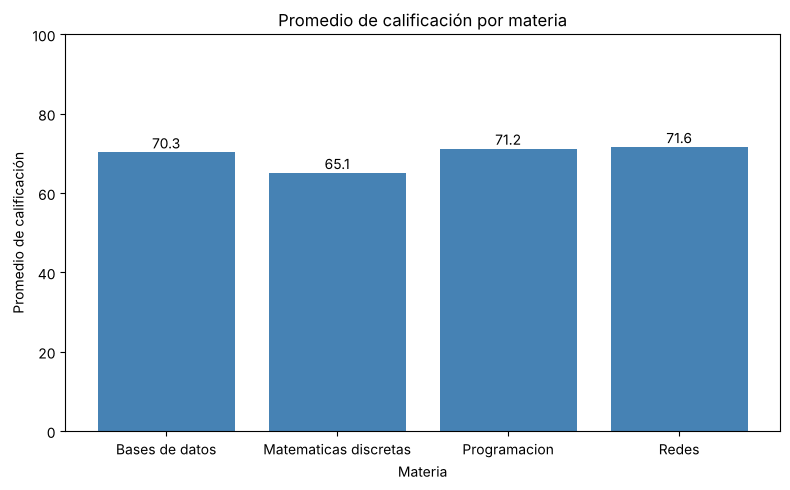

In [7]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(prom_materia.index, prom_materia.values, color="steelblue")
ax1.set_ylim(0, 100)
ax1.set_title("Promedio de calificación por materia")
ax1.set_xlabel("Materia")
ax1.set_ylabel("Promedio de calificación")
for i, v in enumerate(prom_materia.values):
    ax1.text(i, v + 1, f"{v:.1f}", ha="center")
fig1.tight_layout()
fig1.savefig("promedio_materias.png", dpi=150)   # primero guardar
plt.show()                                       # después mostrar

### 5.2 Histograma de todas las calificaciones

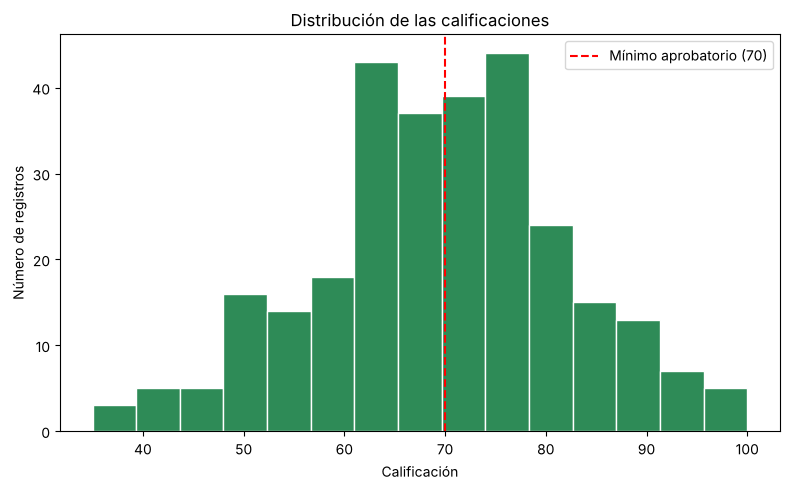

In [8]:
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.hist(df["calificacion"], bins=15, color="seagreen", edgecolor="white")
ax2.axvline(70, color="red", linestyle="--", label="Mínimo aprobatorio (70)")
ax2.set_title("Distribución de las calificaciones")
ax2.set_xlabel("Calificación")
ax2.set_ylabel("Número de registros")
ax2.legend()
fig2.tight_layout()
fig2.savefig("histograma.png", dpi=150)
plt.show()

### 5.3 Gráfica de líneas: promedio por unidad, una línea por materia

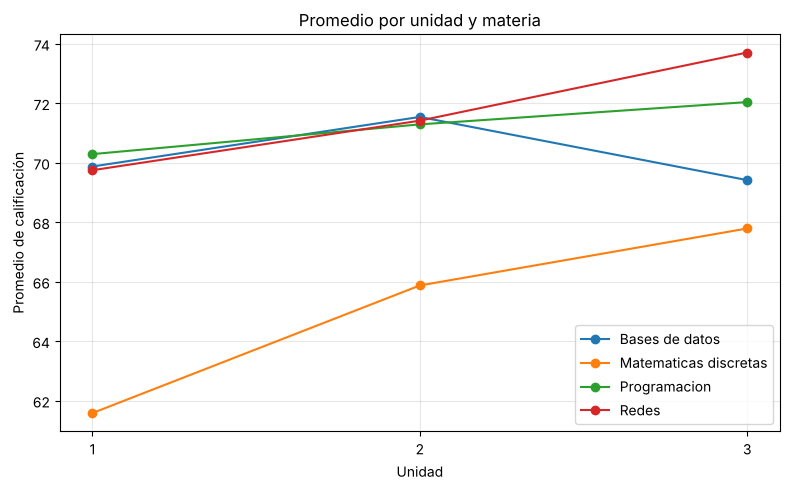

In [9]:
tendencia = df.groupby(["unidad", "materia"])["calificacion"].mean().unstack()

fig3, ax3 = plt.subplots(figsize=(8, 5))
for materia in tendencia.columns:
    ax3.plot(tendencia.index, tendencia[materia], marker="o", label=materia)
ax3.set_xticks([1, 2, 3])
ax3.set_title("Promedio por unidad y materia")
ax3.set_xlabel("Unidad")
ax3.set_ylabel("Promedio de calificación")
ax3.legend()
ax3.grid(alpha=0.3)
fig3.tight_layout()
fig3.savefig("tendencia_unidades.png", dpi=150)
plt.show()

## Ejercicio 6. Lectura de resultados

In [10]:
materia_baja = prom_materia.idxmin()
u1, u2, u3 = prom_unidad.loc[1], prom_unidad.loc[2], prom_unidad.loc[3]
u3_menor = u3 < u1 and u3 < u2
alumnos_bajo_70 = int((prom_alumno["promedio"] < 70).sum())
total_alumnos = len(prom_alumno)

print(f"1) La materia con el promedio más bajo es {materia_baja} ({prom_materia[materia_baja]:.2f}).")
print(f"2) Promedio por unidad: U1 = {u1:.2f}, U2 = {u2:.2f}, U3 = {u3:.2f}. "
      f"El promedio de la unidad 3 {'SÍ' if u3_menor else 'NO'} es menor que el de las unidades 1 y 2.")
print(f"3) {alumnos_bajo_70} de {total_alumnos} alumnos quedan bajo 70 en su promedio general.")

1) La materia con el promedio más bajo es Matematicas discretas (65.08).
2) Promedio por unidad: U1 = 67.88, U2 = 70.03, U3 = 70.74. El promedio de la unidad 3 NO es menor que el de las unidades 1 y 2.
3) 14 de 24 alumnos quedan bajo 70 en su promedio general.


### Interpretación
*(Completa con los números que imprime la celda anterior)*

- La materia con el promedio más bajo es ______ con ______.
- El promedio de la unidad 3 (____) ____ es menor que el de la unidad 1 (____) y la unidad 2 (____).
- ____ alumnos tienen promedio general menor a 70.